# Machine Learning - Telco Churn Prediction
This project uses machine learning to predict whether a tech customer is likely to leave the company (churn) based on their subscribed services, contract details and billing information.

More details: https://github.com/rxr20/machinelearning_telco_churn


## 0. SETUP

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV, RepeatedStratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

from scipy.stats import randint, uniform, loguniform

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from IPython.display import display, Markdown

plt.rcParams["figure.figsize"] = (6.7, 3)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["red", "green", "blue"])

df = pd.read_csv("https://raw.githubusercontent.com/rxr20/Simple-Machine-Learning-Public-Datasets/refs/heads/main/Customer%20Churn/Customer-Churn.csv")

TARGET = "Churn"
RANDOM_STATE = 41

ROUNDPOINT = 2
TEST_PERCENT = 0.2


display(df.head())




,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.DATA EXPLORATION


### Data Exploration Results

📐Data dimensionality: 7043 samples, 21 features
🎯 Target distribution: {'No': '5174 (73.5%)', 'Yes': '1869 (26.5%)'}
🔍 Null values: 0
🔍 Blank values: 11
🔍 Columns with blank values: [('TotalCharges', 11)]


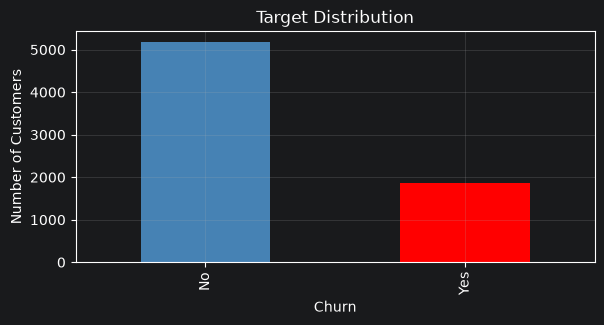

In [38]:
display(Markdown("### Data Exploration Results"))

print("📐Data dimensionality:", df.shape[0],"samples,", df.shape[1], "features" )
print("🎯 Target distribution:", {k: f"{v} ({v/len(df):.1%})" for k, v in df[TARGET].value_counts().items()})
print("🔍 Null values:", df.isnull().sum().sum())
print("🔍 Blank values:", (df == " ").sum().sum())
print("🔍 Columns with blank values:", [(col, count) for col, count in (df == " ").sum().items() if count > 0])

df[TARGET].value_counts().plot(kind="bar", title="Target Distribution", xlabel="Churn", ylabel="Number of Customers", color=["steelblue", "red"]);




##### 🔎 ANALYSIS: Many customers pay 20, and another smaller spike is around 80.

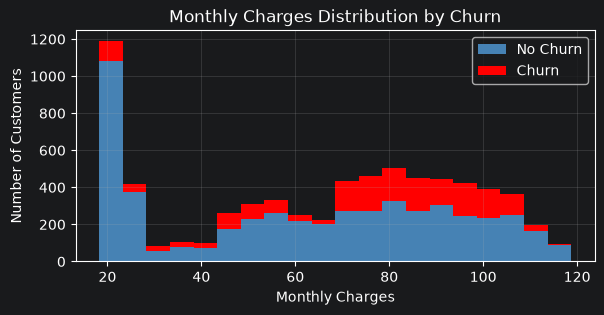

In [39]:
bins = np.linspace(df["MonthlyCharges"].min(), df["MonthlyCharges"].max(), 21)
churn = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]
no_churn = df.loc[df["Churn"] == "No", "MonthlyCharges"]

plt.hist([no_churn, churn], bins=bins, stacked=True, label=["No Churn", "Churn"], color=["steelblue", "red"])
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.legend()
display(Markdown("##### 🔎 ANALYSIS: Many customers pay 20, and another smaller spike is around 80."))

##### 🔎 ANALYSIS: Many customers churn in the first months of tenure, especially in the first month.

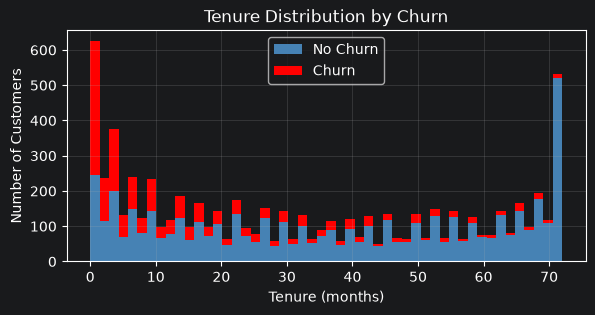

In [40]:
bins = np.linspace(df["tenure"].min(), df["tenure"].max(), 51)
churn = df.loc[df["Churn"] == "Yes", "tenure"]
no_churn = df.loc[df["Churn"] == "No", "tenure"]

plt.hist([no_churn, churn], bins=bins, stacked=True, label=["No Churn", "Churn"], color=["steelblue", "red"])
plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.legend()
display(Markdown("##### 🔎 ANALYSIS: Many customers churn in the first months of tenure, especially in the first month."))

##### 🔎 ANALYSIS: It looks like most customers churn in their first year of service.

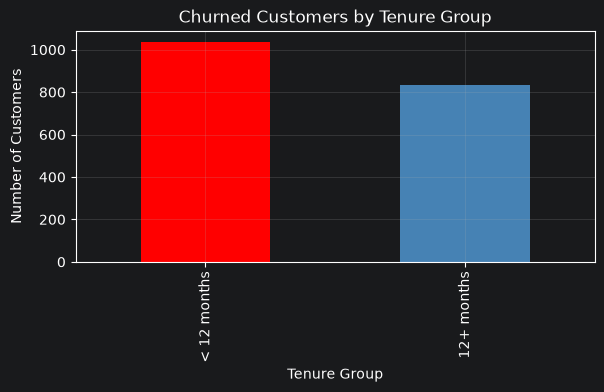

In [41]:
cutoff = 12

churn_tenure = pd.Series({f"< {cutoff} months": ((df["Churn"] == "Yes") & (df["tenure"] <= cutoff)).sum(), f"{cutoff}+ months": ((df["Churn"] == "Yes") & (df["tenure"] > cutoff)).sum()})
churn_tenure.plot(kind="bar", title="Churned Customers by Tenure Group", xlabel="Tenure Group", ylabel="Number of Customers", color=["red", "steelblue"])

display(Markdown("##### 🔎 ANALYSIS: It looks like most customers churn in their first year of service."))

##### 🔎 ANALYSIS: People who use Electronic check seem more likely to churn.

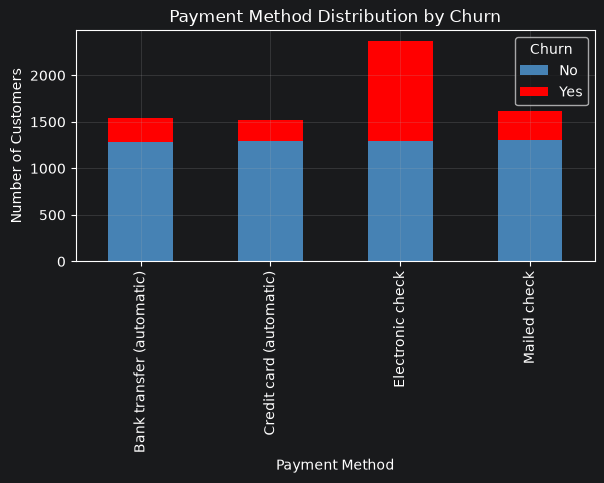

In [42]:
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"])[["No", "Yes"]]
payment_churn.plot(kind="bar", stacked=True, title="Payment Method Distribution by Churn", xlabel="Payment Method", ylabel="Number of Customers", color=["steelblue", "red"])
display(Markdown("##### 🔎 ANALYSIS: People who use Electronic check seem more likely to churn."))

##### 🔎 ANALYSIS: Most people who churn have a monthly contract. Few churn from those who have a one year contract, and even less for the two year contract.

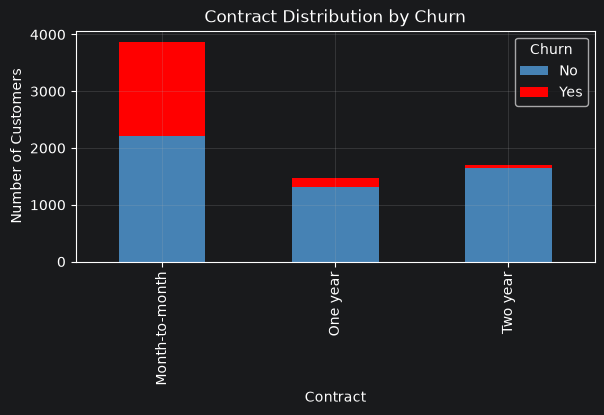

In [43]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"])[["No", "Yes"]]
contract_churn.plot(kind="bar", stacked=True, title="Contract Distribution by Churn", xlabel="Contract", ylabel="Number of Customers", color=["steelblue", "red"])
display(Markdown("##### 🔎 ANALYSIS: Most people who churn have a monthly contract. Few churn from those who have a one year contract, and even less for the two year contract."))

##### 🔎 ANALYSIS: Customers who already paid a lot for services are less likely to churn. 

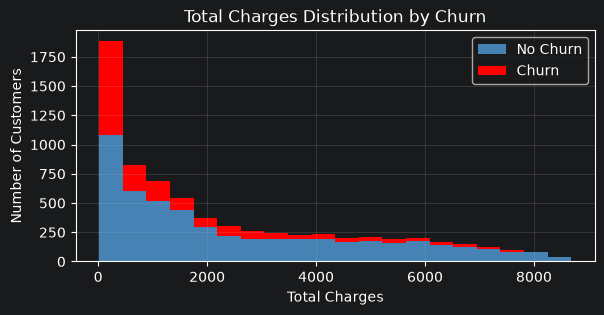

In [44]:
total_charges_plot = pd.to_numeric(df["TotalCharges"], errors="coerce")
bins = np.linspace(total_charges_plot.min(), total_charges_plot.max(), 21)

churn = pd.to_numeric(df.loc[df["Churn"] == "Yes", "TotalCharges"], errors="coerce").dropna()
no_churn = pd.to_numeric(df.loc[df["Churn"] == "No", "TotalCharges"], errors="coerce").dropna()

plt.hist([no_churn, churn], bins=bins, stacked=True, label=["No Churn", "Churn"], color=["steelblue", "red"])
plt.title("Total Charges Distribution by Churn")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.legend()
display(Markdown("##### 🔎 ANALYSIS: Customers who already paid a lot for services are less likely to churn. "))

##### 🔎 ANALYSIS: A closer look at the tenure month when customers tend to churn shows that customers churn often in the first months 

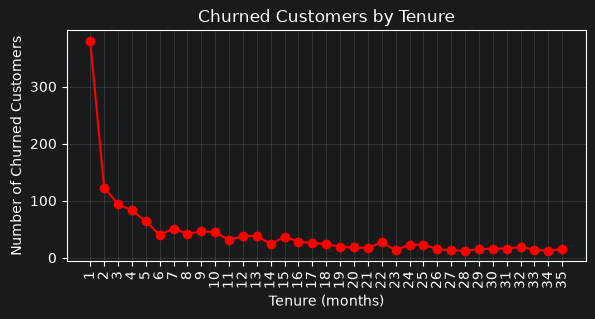

In [45]:
churn_by_tenure = df.loc[df["Churn"] == "Yes"].groupby("tenure").size().reindex(range(1, 36), fill_value=0)

ax = churn_by_tenure.plot(kind="line", marker="o", title="Churned Customers by Tenure", xlabel="Tenure (months)", ylabel="Number of Churned Customers")
ax.set_xticks(range(1, 36))
ax.set_xticklabels(range(1, 36), rotation=90)
display(Markdown("##### 🔎 ANALYSIS: A closer look at the tenure month when customers tend to churn shows that customers churn often in the first months "))

In [46]:
Xtemp = df.drop(columns=["customerID", "Churn"]).copy()
ytemp = df["Churn"].map({"No": 0, "Yes": 1})

Xtemp["TotalCharges"] = pd.to_numeric(Xtemp["TotalCharges"], errors="coerce").fillna(0)
Xtemp = pd.get_dummies(Xtemp, drop_first=True)

rf_eda = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_eda.fit(Xtemp, ytemp)

importance = pd.Series(rf_eda.feature_importances_, index=Xtemp.columns).sort_values(ascending=False)

print(importance.round(3))
display(Markdown("##### 🔎 ANALYSIS: A quick look at features importance suggests that TotalCharges is the most important field."))

TotalCharges                             0.196
MonthlyCharges                           0.172
tenure                                   0.170
InternetService_Fiber optic              0.038
PaymentMethod_Electronic check           0.035
Contract_Two year                        0.032
gender_Male                              0.028
OnlineSecurity_Yes                       0.026
PaperlessBilling_Yes                     0.025
TechSupport_Yes                          0.024
Partner_Yes                              0.023
Contract_One year                        0.023
OnlineBackup_Yes                         0.022
SeniorCitizen                            0.021
MultipleLines_Yes                        0.020
Dependents_Yes                           0.020
DeviceProtection_Yes                     0.019
StreamingMovies_Yes                      0.017
StreamingTV_Yes                          0.017
PaymentMethod_Credit card (automatic)    0.014
PaymentMethod_Mailed check               0.012
OnlineBackup_

##### 🔎 ANALYSIS: A quick look at features importance suggests that TotalCharges is the most important field.

### 📊 Data Exploration Analysis

💡The dataset contains a lot **more customers who haven't terminated their contract** (almost 75% have Churn = No)

💡Many of the customers pay around 20 monthly. But the **majority of customers have extra options** and pay more than 20, with a noticeable spike around the 80 price range

💡The tenure distribution indicates that there are many customers who are in their first couple of months. The number then drops dramatically, suggesting that **customers tend to churn often in their first 5 months**.

💡There is a **very large spike around 72 months**, which suggests that tenure data is limited to 6 years. But given the large number of customers with this tenure, 72 might represent an upper limit/boundary in the recorded data

💡The **payment method distribution** between the 4 categories shows that Electronic checks is more used, while the other options have similarily slightly lower counts




### 📊 Model Analysis

❗ Since the target of the model is the Churn information, which is a Yes/No value, then the best model to choose for this problem is a **classification model**.

💡 Between False Positives and False Negatives, more costly IRL are likely the **False Negatives**, because these represent customers that are going to churn and haven't been identified by the model. With the help of the model, the company can reach out to customers with offers which might sway them to stay longer. These offers would likely be less costly to be given to False Negative cases , than the cost incurred from losing with the False Positives.



## 2.DATA PREP
❗ We split the data and keep the test values only for the final test **in order to get an accurate test result** and to avoid the test data to bias the training of the model.

In [47]:
cat_cols = [
    "Partner", "Dependents", "PhoneService",
    "PaperlessBilling", "SeniorCitizen", "Contract",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "PaymentMethod",
    "is_new", "auto_pay", "fiber_no_support"
]

num_cols = [
    "tenure", "MonthlyCharges", "TotalCharges",
    "avg_charge", "charge_diff", "n_services"
]

service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "PhoneService", "MultipleLines"
]

internet_services = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")


# Simplify services
df[service_cols] = df[service_cols].replace({
    "No internet service": "No",
    "No phone service": "No"
})

# New features
df["n_services"] = (
    (df[service_cols] == "Yes").sum(axis=1)
)

df["avg_charge"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
)

df["charge_diff"] = df["MonthlyCharges"] - df["avg_charge"]

df["is_new"] = (df["tenure"] <= 6).astype(int)

df["auto_pay"] = (
    df["PaymentMethod"].str.contains("automatic", case=False, na=False).astype(int)
)

df["fiber_no_support"] = (
    (df["InternetService"] == "Fiber optic") &
    (df["TechSupport"] != "Yes") &
    (df["InternetService"] != "No")
).astype(int)

FEATURES = df.drop(columns=["customerID", "Churn","gender"]).columns.tolist()

X, y = df[FEATURES], df[TARGET].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_PERCENT,
    random_state=RANDOM_STATE, stratify=y
)



preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)


## 3.BASELINE
❗ We set up a baseline dummy model to see how well could a simple model who is not trained do on this dataset.
In this case, a model that would always predict that the customer won't churn (the most likely option), would have an **accuracy score of 73%**

In [48]:
dummy = DummyClassifier(strategy="most_frequent")

dummy_scores = cross_validate(
    dummy, X_train, y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

print("Dummy Baseline")
print("CV Accuracy:", round(dummy_scores["test_accuracy"].mean(), ROUNDPOINT))
print("CV Precision:", round(dummy_scores["test_precision"].mean(), ROUNDPOINT))
print("CV Recall:", round(dummy_scores["test_recall"].mean(), ROUNDPOINT))
print("CV F1:", round(dummy_scores["test_f1"].mean(), ROUNDPOINT))

Dummy Baseline
CV Accuracy: 0.73
CV Precision: 0.0
CV Recall: 0.0
CV F1: 0.0


## 4.TRAIN MODELS


### 4.1 XGBOOST MODEL
Training a XGBoost model. Trying different parameters using RandomizedSearchCV. There will be 80 combinations tried for this model, each with cross validation.

In [49]:
xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ))
])

param_distributions = {
    "model__n_estimators": randint(200, 800),
    "model__max_depth": randint(2, 6),
    "model__learning_rate": loguniform(0.01, 0.1),
    "model__min_child_weight": randint(1, 20),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(1e-3, 100),
    "model__reg_alpha": loguniform(1e-3, 10),
    "model__gamma": uniform(0, 2),
}

random_search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_distributions,
    n_iter=80,
    cv=cv,
    scoring="f1",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

random_search_xgb.fit(X_train, y_train)

best_xgb = random_search_xgb.best_estimator_

xgb_scores = cross_validate(
    best_xgb, X_train, y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

print("XGBoost")
print("Best Parameters:", random_search_xgb.best_params_)
print("CV Accuracy:", round(xgb_scores["test_accuracy"].mean(), ROUNDPOINT))
print("CV Precision:", round(xgb_scores["test_precision"].mean(), ROUNDPOINT))
print("CV Recall:", round(xgb_scores["test_recall"].mean(), ROUNDPOINT))
print("CV F1:", round(xgb_scores["test_f1"].mean(), ROUNDPOINT))

Fitting 5 folds for each of 80 candidates, totalling 400 fits
XGBoost
Best Parameters: {'model__colsample_bytree': np.float64(0.574466597787703), 'model__gamma': np.float64(0.8734082486983032), 'model__learning_rate': np.float64(0.03353449311646584), 'model__max_depth': 3, 'model__min_child_weight': 15, 'model__n_estimators': 403, 'model__reg_alpha': np.float64(0.05186888026757326), 'model__reg_lambda': np.float64(55.97318457386118), 'model__subsample': np.float64(0.8736353006502172)}
CV Accuracy: 0.8
CV Precision: 0.66
CV Recall: 0.55
CV F1: 0.6


### 4.2 LOGISTIC REGRESSION MODEL
We try also a Logistic Regression model to see how well it does on this dataset.

In [50]:
logreg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        random_state=RANDOM_STATE
    ))
])

param_distributions = {
    "model__C": loguniform(0.001, 100),
    "model__max_iter": [500, 1000, 2000, 3000],
    "model__solver": ["lbfgs", "liblinear"],
    "model__class_weight": [None, "balanced"]
}

random_search_logreg = RandomizedSearchCV(
    estimator=logreg,
    param_distributions=param_distributions,
    n_iter=30,
    cv=cv,
    scoring="f1",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

random_search_logreg.fit(X_train, y_train)

best_logreg = random_search_logreg.best_estimator_


logreg_scores = cross_validate(
    best_logreg, X_train, y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

print("Logistic Regression")
print("Best Parameters:", random_search_logreg.best_params_)
print("CV Accuracy:", round(logreg_scores["test_accuracy"].mean(), ROUNDPOINT))
print("CV Precision:", round(logreg_scores["test_precision"].mean(), ROUNDPOINT))
print("CV Recall:", round(logreg_scores["test_recall"].mean(), ROUNDPOINT))
print("CV F1:", round(logreg_scores["test_f1"].mean(), ROUNDPOINT))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Logistic Regression
Best Parameters: {'model__C': np.float64(0.00598131555626867), 'model__class_weight': 'balanced', 'model__max_iter': 3000, 'model__solver': 'liblinear'}
CV Accuracy: 0.76
CV Precision: 0.53
CV Recall: 0.79
CV F1: 0.63


### 4.4 COMPARE MODELS
❗ We compare the two models created earlier. XGBoost has a better Precision while Logistic Regression has a higher Recall. The logistic Regression model therefore predicts more often that the customer will churn, it catches more of the churn cases but at the cost of making more wrong predictions.The XGBoost model is more precise, but it predicts fewer of the churners. XGBoost is able to find more complex patterns and that helps it be more precise. Logistic Regression tries to capture a formula/relationship between features so it generalizes more.

In [51]:
cv_results = [
    ["Baseline", dummy_scores["test_accuracy"].mean(), dummy_scores["test_precision"].mean(), dummy_scores["test_recall"].mean(),dummy_scores["test_f1"].mean()],
    ["XGBoost", xgb_scores["test_accuracy"].mean(), xgb_scores["test_precision"].mean(), xgb_scores["test_recall"].mean(), xgb_scores["test_f1"].mean()],
    ["Logistic Regression", logreg_scores["test_accuracy"].mean(), logreg_scores["test_precision"].mean(), logreg_scores["test_recall"].mean(), logreg_scores["test_f1"].mean()]
]

cv_results = pd.DataFrame(
    cv_results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

display(cv_results.round(ROUNDPOINT))

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.73,0.00,0.00,0.00
1,XGBoost,0.80,0.66,0.55,0.60
2,Logistic Regression,0.76,0.53,0.79,0.63


### 4.5 PICKING XGBOOST & DOING FINE TUNE ON THRESHOLD


In [52]:
best_model = best_xgb

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.46, 0.54, 0.001):
    p = (oof >= t).astype(int)
    rows.append([t, accuracy_score(y_train, p), f1_score(y_train, p)])
th = pd.DataFrame(rows, columns=["threshold", "accuracy", "f1"])



best_row = (
    th.assign(f1_rounded=th["f1"].round(2))
      .sort_values(["f1_rounded", "accuracy"], ascending=False)
      .iloc[0]
)

best_t = best_row["threshold"]

print("Best threshold:", round(best_t, ROUNDPOINT))
print("F1:", round(best_row["f1"], ROUNDPOINT))
print("Accuracy:", round(best_row["accuracy"], ROUNDPOINT))

Best threshold: 0.47
F1: 0.61
Accuracy: 0.8


### 5. TEST DATA EVALUATION
Testing the the model with the custom threshold on the **final test values**.

❗ The model was optimized to do well on the F1 metric, for a good balance between Precision & Recall.


In [53]:

p_test = best_model.predict_proba(X_test)[:, 1]
final_pred = (p_test >= best_t).astype(int)

print("=" * 32)
print("       FINAL TEST RESULTS")
print("=" * 32)
print("Accuracy:", round(accuracy_score(y_test, final_pred), ROUNDPOINT))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), ROUNDPOINT))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), ROUNDPOINT))
print("F1:", round(f1_score(y_test, final_pred, zero_division=0), ROUNDPOINT))
print("=" * 32)

       FINAL TEST RESULTS
Accuracy: 0.81
Precision: 0.65
Recall: 0.58
F1: 0.62


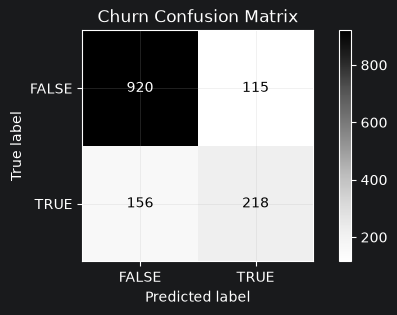

In [54]:
cm = confusion_matrix(y_test, final_pred)

ConfusionMatrixDisplay(cm, display_labels=["FALSE", "TRUE"]).plot(cmap="Greys")

plt.title("Churn Confusion Matrix")
plt.show()

### 6. CONCLUSION

❗ Logistic Regression could do well if the purpose of the model is to catch as many of the possible churners (at the cost of making many false alarm predictions), and it would be faster than XGBoost. But for a more general purpose of making Churn/No-Churn predictions, for better balance, XGBoost seems to be a very good solution for this dataset.

❗ The baseline dummy model had an accuracy score of .72. This model has an accuracy score of .80-.81, and is able to make Churn predictions that are 65% of the time correct, as well as capture more than half (~57%) of the churn cases.


